# Лабораторная работа 1. Байесовская оптимизация гиперпараметров

In [ ]:
%pip install -q numpy pandas scipy scikit-learn matplotlib optuna lightgbm SALib

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from lightgbm import LGBMClassifier

import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [ ]:
SEED = 42
N_TRIALS = 60
N_INITIAL = 15
N_CANDIDATES = 5000 # фактически удваивается -- N_CANDIDATES для случайных глобальных точек и N_CANDIDATES для локальных точек вокруг текущего лучшего решения

## 1. Алгоритм и гиперпараметры

В качестве алгортима выбран LGBMClassifier. Оптимизируются гиперпараметры:

| параметр | смысл | диапазон |
|---|---|---|
| `n_estimators` | число деревьев | 50–800 |
| `learning_rate` | шаг бустинга | 0.003–0.3 |
| `num_leaves` | число листьев в дереве | 4–256 |
| `min_child_samples` | минимум объектов в листе | 5–150 |
| `min_child_weight` | минимум суммы гессианов в листе | 1e-4–10 |
| `min_split_gain` | минимальный выигрыш для сплита | 0–1 |
| `subsample` | доля объектов для дерева | 0.5–1 |
| `subsample_freq` | частота бэггинга | 1–10 |
| `colsample_bytree` | доля признаков для дерева | 0.5–1 |
| `reg_alpha` | L1-регуляризация | 1e-8–10 |
| `reg_lambda` | L2-регуляризация | 1e-8–10 |
| `max_bin` | число бинов гистограммы | 32–1023 |
| `extra_trees` | случайные пороги сплитов | False / True |

In [ ]:
SPACE = [
    ("n_estimators",      50,    800,  "int",   False),
    ("learning_rate",     0.003, 0.3,  "float", True),
    ("num_leaves",        4,     256,  "int",   True),
    ("min_child_samples", 5,     150,  "int",   True),
    ("min_child_weight",  1e-4,  10.0, "float", True),
    ("min_split_gain",    0.0,   1.0,  "float", False),
    ("subsample",         0.5,   1.0,  "float", False),
    ("subsample_freq",    1,     10,   "int",   False),
    ("colsample_bytree",  0.5,   1.0,  "float", False),
    ("reg_alpha",         1e-8,  10.0, "float", True),
    ("reg_lambda",        1e-8,  10.0, "float", True),
    ("max_bin",           32,    1023,  "int",   False),
    ("extra_trees",       0,     1,    "bool",  False),
]
PARAM_NAMES = [item[0] for item in SPACE]
D = len(SPACE)


def clean_value(low, high, kind, value):
    value = min(max(value, low), high)
    if kind == "int":
        return int(round(value))
    if kind == "bool":
        return bool(value >= 0.5)
    return float(value)


def sample_params(rng):
    params = {}
    for name, low, high, kind, log in SPACE:
        if log:
            value = np.exp(rng.uniform(np.log(low), np.log(high)))
        else:
            value = rng.uniform(low, high)
        params[name] = clean_value(low, high, kind, value)
    return params


def perturb(params, rng, step=0.05):
    new_params = {}
    for name, low, high, kind, log in SPACE:
        if kind == "bool":
            flip = rng.random() < 0.2
            new_params[name] = (not params[name]) if flip else params[name]
        elif log:
            width = np.log(high) - np.log(low)
            value = np.exp(np.log(params[name]) + rng.normal(0, step * width))
            new_params[name] = clean_value(low, high, kind, value)
        else:
            value = params[name] + rng.normal(0, step * (high - low))
            new_params[name] = clean_value(low, high, kind, value)
    return new_params


def to_features(params):
    return np.array([np.log(params[name]) if log else float(params[name])
                     for name, low, high, kind, log in SPACE])


def from_features(features):
    params = {}
    for value, (name, low, high, kind, log) in zip(features, SPACE):
        params[name] = clean_value(low, high, kind, np.exp(value) if log else value)
    return params


FEATURE_BOUNDS = [(np.log(low), np.log(high)) if log else (low, high)
                  for name, low, high, kind, log in SPACE]

In [ ]:
print(sample_params(np.random.default_rng(0)))

{'n_estimators': 528, 'learning_rate': 0.010391893379675408, 'num_leaves': 5, 'min_child_samples': 5, 'min_child_weight': 1.1650677907562472, 'min_split_gain': 0.9127555772777217, 'subsample': 0.8033178878835899, 'subsample_freq': 8, 'colsample_bytree': 0.7718124957327115, 'reg_alpha': 2.6040649618948253, 'reg_lambda': 0.2201313956688175, 'max_bin': 35, 'extra_trees': True}


## 2. Данные и целевая функция

phoneme — 5,4 тыс. объектов, 5 числовых признаков, бинарный таргет. Пропусков, дат и категориальных признаков нет

Минимизируем функцию:
$$
f(\theta) = \frac{1}{K} \sum_{k=1}^{K} \mathrm{LogLoss}\big(y_{V_k}, \hat{p}_{\theta,k}(X_{V_k})\big) \longrightarrow \min_{\theta}, \qquad K = 5
$$

In [ ]:
data = fetch_openml(data_id=1489, as_frame=True, parser="auto")
X = data.data.astype(float)
y = LabelEncoder().fit_transform(data.target)

print("Размер:", X.shape)
print("Пропусков:", int(X.isna().sum().sum()))
print("Доли классов:", np.bincount(y) / len(y))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def objective(params):
    model = LGBMClassifier(**params, random_state=SEED, n_jobs=1, verbosity=-1)
    scores = cross_val_score(model, X, y, cv=cv, scoring="neg_log_loss", n_jobs=-1)
    return -scores.mean()

Размер: (5404, 5)
Пропусков: 0
Доли классов: [0.70651369 0.29348631]


## 3. Байесовская оптимизация и случайный поиск

Байесовская оптимизация:
1. Первые N_INITIAL точек выбираются случайно. Генератор случайных чисел инициализирован тем же сидом, что и у случайного поиска, поэтому стартовые точки у двух методов совпадают
2. Суррогат — случайный лес. Прогноз в точке — среднее по деревьям, неопределённость — стандартное отклонение предсказаний деревьев
3. Функция улучшения — Expected Improvement для минимизации:
$$\mathrm{EI}(x) = (f^* - \mu(x) - \xi)\,\Phi(z) + \sigma(x)\,\varphi(z),\qquad z = \frac{f^* - \mu(x) - \xi}{\sigma(x)},$$

4. Следующая точка — кандидат с максимальным EI. Кандидаты: N_CANDIDATES случайных точек и столько же точек рядом с текущей лучшей

In [ ]:
def random_search(n_trials, seed):
    rng = np.random.default_rng(seed)
    history = []
    for step in range(n_trials):
        params = sample_params(rng)
        history.append({"step": step + 1, "loss": objective(params), **params})
    return pd.DataFrame(history)


def expected_improvement(mean, std, best, xi):
    std = np.maximum(std, 1e-9)
    z = (best - mean - xi) / std
    return (best - mean - xi) * norm.cdf(z) + std * norm.pdf(z)


def bayesian_optimization(n_trials, n_initial, seed):
    rng = np.random.default_rng(seed)
    observed, losses, history = [], [], []
    for step in range(n_trials):
        if step < n_initial:
            params = sample_params(rng)
        else:
            forest = RandomForestRegressor(n_estimators=200, max_features=0.5, random_state=seed)
            forest.fit(np.array([to_features(p) for p in observed]), np.array(losses))

            best_params = observed[int(np.argmin(losses))]
            candidates = ([sample_params(rng) for i in range(N_CANDIDATES)]
                          + [perturb(best_params, rng) for i in range(N_CANDIDATES)])
            features = np.array([to_features(p) for p in candidates])

            tree_predictions = np.array([tree.predict(features) for tree in forest.estimators_])
            mean = tree_predictions.mean(axis=0)
            std = tree_predictions.std(axis=0)
            ei = expected_improvement(mean, std, min(losses), xi=0.01 * np.std(losses))
            params = candidates[int(np.argmax(ei))]

        loss = objective(params)
        observed.append(params)
        losses.append(loss)
        history.append({"step": step + 1, "loss": loss, **params})
    return pd.DataFrame(history)

In [ ]:
results = {}
times = {}

start = time.perf_counter()
results["Байесовская оптимизация"] = bayesian_optimization(N_TRIALS, N_INITIAL, SEED)
times["Байесовская оптимизация"] = time.perf_counter() - start

start = time.perf_counter()
results["Случайный поиск"] = random_search(N_TRIALS, SEED)
times["Случайный поиск"] = time.perf_counter() - start

## 4. Сравнение

In [ ]:
def summary(results, times):
    rows = []
    for name, df in results.items():
        best = df.loc[df["loss"].idxmin()]
        rows.append({
            "метод": name,
            "лучший log loss": round(best["loss"], 4),
            "шаг лучшей точки": int(best["step"]),
            "время, с": round(times[name], 1),
        })
    return pd.DataFrame(rows).set_index("метод")


summary(results, times)

,лучший log loss,шаг лучшей точки,"время, с"
метод,,,
Байесовская оптимизация,0.2380,53,465.2
Случайный поиск,0.2435,32,90.1


## 5. Значение целевой функции в зависимости от номера шага

Слева — значение на каждом шаге, справа — лучшее значение, найденное к этому шагу. Пунктир — конец случайного старта байесовской оптимизации.

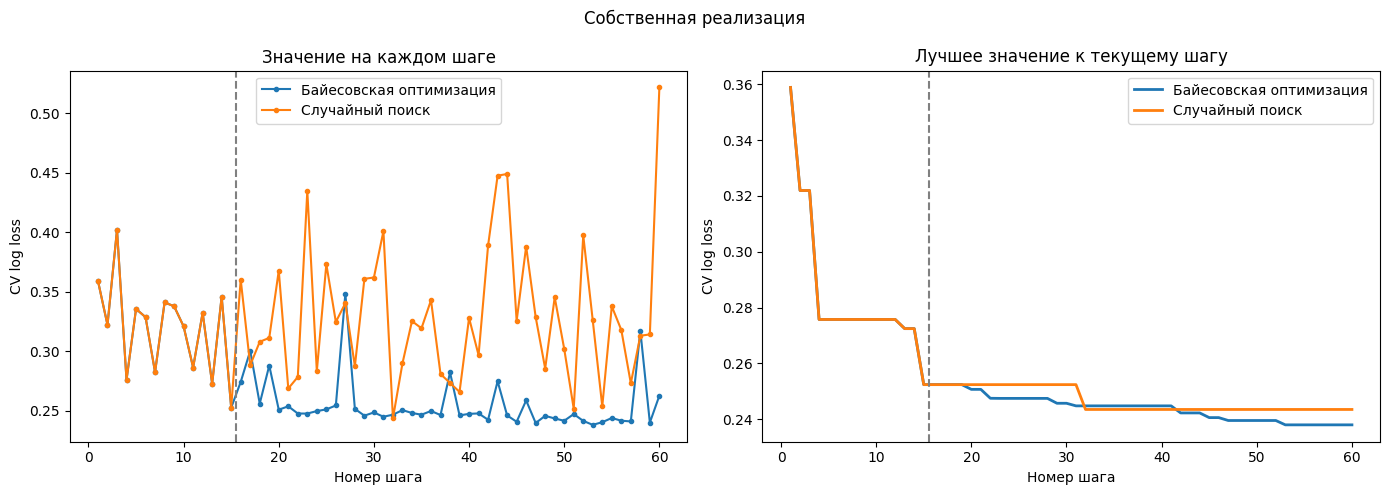

In [ ]:
def plot_steps(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name, df in results.items():
        axes[0].plot(df["step"], df["loss"], marker="o", markersize=3, label=name)
        axes[1].plot(df["step"], df["loss"].cummin(), linewidth=2, label=name)
    axes[0].set_title("Значение на каждом шаге")
    axes[1].set_title("Лучшее значение к текущему шагу")
    for ax in axes:
        ax.axvline(N_INITIAL + 0.5, color="grey", linestyle="--")
        ax.set_xlabel("Номер шага")
        ax.set_ylabel("CV log loss")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_steps(results, "Собственная реализация")

## 6. Пространство протестированных гиперпараметров

Точки проецируются на плоскость методом главных компонент. Бинарный `extra_trees` в проекцию не входит: его дисперсия в кубе (0.25) втрое больше, чем у равномерного непрерывного параметра (1/12), и он один задавал бы первую компоненту. Цвет — значение целевой функции, звезда — лучшая точка.

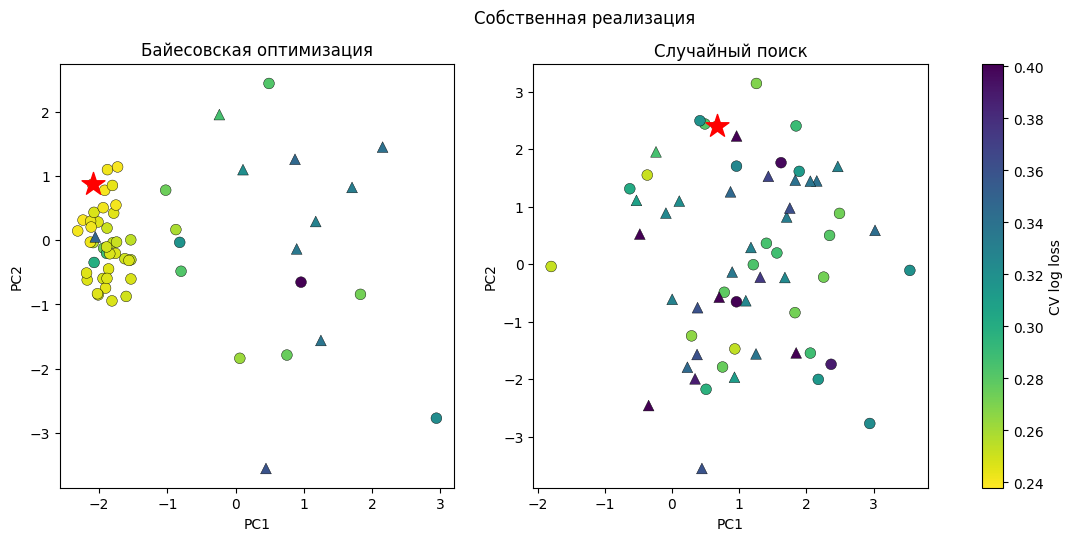

In [ ]:
CONTINUOUS = [name for name, low, high, kind, log in SPACE if kind != "bool"]


def feature_matrix(df):
    return np.array([to_features(row) for row in df[PARAM_NAMES].to_dict("records")])


def plot_space(results, title):
    columns = [PARAM_NAMES.index(name) for name in CONTINUOUS]
    matrices = {name: feature_matrix(df)[:, columns] for name, df in results.items()}
    stacked = np.vstack(list(matrices.values()))
    center, scale = stacked.mean(axis=0), stacked.std(axis=0)
    matrices = {name: (m - center) / scale for name, m in matrices.items()}
    pca = PCA(n_components=2).fit(np.vstack(list(matrices.values())))

    all_losses = pd.concat(results.values())["loss"]
    vmin, vmax = all_losses.min(), np.quantile(all_losses, 0.95)

    fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5))
    for ax, (name, df) in zip(axes, results.items()):
        points = pca.transform(matrices[name])
        is_extra = df["extra_trees"].astype(bool).to_numpy()
        losses = df["loss"].to_numpy()
        for flag, marker in [(False, "o"), (True, "^")]:
            mask = is_extra == flag
            scatter = ax.scatter(points[mask, 0], points[mask, 1], c=losses[mask],
                                 cmap="viridis_r", vmin=vmin, vmax=vmax, marker=marker,
                                 s=60, edgecolor="black", linewidth=0.3,
                                 label=f"extra_trees = {flag}")
        best = int(df["loss"].idxmin())
        ax.scatter(points[best, 0], points[best, 1], marker="*", s=300, color="red")
        ax.set_title(name)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
    fig.colorbar(scatter, ax=axes, label="CV log loss")
    fig.suptitle(f"{title}")
    plt.show()


plot_space(results, "Собственная реализация")

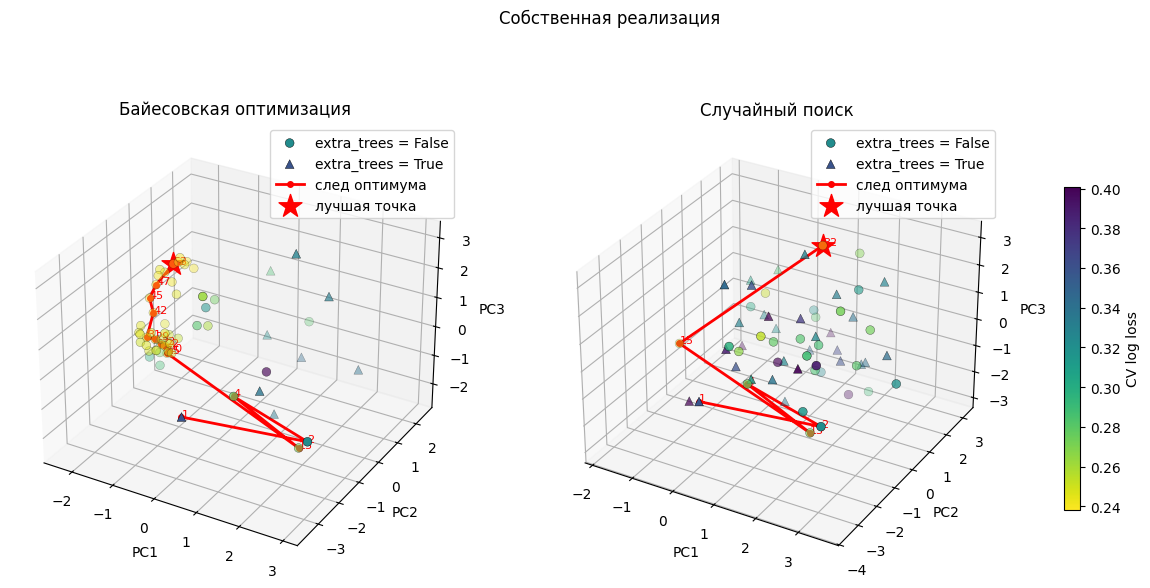

In [ ]:
def plot_space_3d(results, title):
    columns = [PARAM_NAMES.index(name) for name in CONTINUOUS]
    matrices = {name: feature_matrix(df)[:, columns] for name, df in results.items()}
    stacked = np.vstack(list(matrices.values()))
    center, scale = stacked.mean(axis=0), stacked.std(axis=0)
    matrices = {name: (m - center) / scale for name, m in matrices.items()}
    pca = PCA(n_components=3).fit(np.vstack(list(matrices.values())))

    all_losses = pd.concat(results.values())["loss"]
    vmin, vmax = all_losses.min(), np.quantile(all_losses, 0.95)

    fig = plt.figure(figsize=(8 * len(results), 7))
    for i, (name, df) in enumerate(results.items(), start=1):
        ax = fig.add_subplot(1, len(results), i, projection="3d")
        points = pca.transform(matrices[name])
        is_extra = df["extra_trees"].astype(bool).to_numpy()
        losses = df["loss"].to_numpy()
        for flag, marker in [(False, "o"), (True, "^")]:
            mask = is_extra == flag
            scatter = ax.scatter(points[mask, 0], points[mask, 1], points[mask, 2],
                                 c=losses[mask], cmap="viridis_r", vmin=vmin, vmax=vmax,
                                 marker=marker, s=40, edgecolor="black", linewidth=0.3,
                                 label=f"extra_trees = {flag}")

        improved = (df["loss"] < df["loss"].cummin().shift(fill_value=np.inf)).to_numpy()
        trace = points[improved]
        ax.plot(trace[:, 0], trace[:, 1], trace[:, 2], color="red", linewidth=2,
                marker="o", markersize=4, label="след оптимума")
        for point, step in zip(trace, df["step"][improved]):
            ax.text(point[0], point[1], point[2], str(step), color="red", fontsize=8)

        best = int(df["loss"].idxmin())
        ax.scatter(*points[best], marker="*", s=300, color="red", label="лучшая точка")

        ax.set_title(name)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_zlabel("PC3")
        ax.legend()

    fig.colorbar(scatter, ax=fig.axes, shrink=0.6, label="CV log loss")
    fig.suptitle(f"{title}")
    plt.show()


plot_space_3d(results, "Собственная реализация")

## 7. Важность гиперпараметров

Задача «гиперпараметры → значение целевой функции» рассматривается как задача регрессии. На ней обучается случайный лес, а важность каждого гиперпараметра оценивается методом перестановочной важности (permutation importance): насколько ухудшается предсказание, если перемешать значения этого параметра.

Точки случайного поиска равномерно покрывают пространство, поэтому важность по ним описывает всю целевую функцию. Точки байесовской оптимизации сосредоточены в хорошей области, и важность по ним описывает в первую очередь эту область.

In [ ]:
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol as sobol_analyze

PROBLEM = {"num_vars": D, "names": PARAM_NAMES, "bounds": [list(b) for b in FEATURE_BOUNDS]}


def sobol_importance(df, n_base=1024):
    features = feature_matrix(df)
    forest = RandomForestRegressor(n_estimators=500, min_samples_leaf=2,
                                   oob_score=True, random_state=SEED)
    forest.fit(features, df["loss"])

    samples = sobol_sample.sample(PROBLEM, n_base, calc_second_order=False, seed=SEED)
    samples = np.array([to_features(from_features(row)) for row in samples])

    result = sobol_analyze.analyze(PROBLEM, forest.predict(samples),
                                   calc_second_order=False, seed=SEED)
    table = pd.DataFrame({"S1": result["S1"], "ST": result["ST"],
                          "ST_conf": result["ST_conf"]}, index=PARAM_NAMES)
    return table, forest.oob_score_


for name, df in {**results}.items():
    table, oob = sobol_importance(df)
    print(f"{name}: OOB R^2 суррогата = {oob:.2f}")
    display(table.sort_values("ST", ascending=False).round(3))

Байесовская оптимизация: OOB R^2 суррогата = 0.63


,S1,ST,ST_conf
extra_trees,0.666,0.723,0.058
num_leaves,0.084,0.117,0.014
subsample,0.095,0.106,0.010
learning_rate,0.048,0.057,0.007
reg_alpha,0.020,0.023,0.003
min_split_gain,0.012,0.015,0.002
colsample_bytree,0.008,0.009,0.001
reg_lambda,0.007,0.006,0.001
min_child_weight,0.005,0.004,0.000
n_estimators,0.001,0.002,0.000


Случайный поиск: OOB R^2 суррогата = 0.64


,S1,ST,ST_conf
learning_rate,0.683,0.722,0.059
extra_trees,0.246,0.284,0.028
n_estimators,0.013,0.018,0.002
min_split_gain,0.001,0.006,0.001
num_leaves,-0.004,0.005,0.001
reg_alpha,0.004,0.004,0.001
min_child_samples,-0.001,0.004,0.000
min_child_weight,0.002,0.003,0.000
subsample,0.001,0.001,0.000
reg_lambda,-0.001,0.001,0.000


## 8. Повторение шагов 4–7 с Optuna

Байесовская оптимизация — `TPESampler`, случайный поиск — `RandomSampler`. Первые `N_INITIAL` точек добавляются через `enqueue_trial` и совпадают со стартовыми точками собственной реализации. Важность считается встроенной в Optuna функцией `get_param_importances` (метод fANOVA).

In [ ]:
def optuna_objective(trial):
    params = {}
    for name, low, high, kind, log in SPACE:
        if kind == "int":
            params[name] = trial.suggest_int(name, low, high, log=log)
        elif kind == "float":
            params[name] = trial.suggest_float(name, low, high, log=log)
        else:
            params[name] = trial.suggest_categorical(name, [False, True])
    return objective(params)


def run_optuna(sampler):
    study = optuna.create_study(direction="minimize", sampler=sampler)
    rng = np.random.default_rng(SEED)
    for step in range(N_INITIAL):
        study.enqueue_trial(sample_params(rng))
    study.optimize(optuna_objective, n_trials=N_TRIALS)
    history = [{"step": t.number + 1, "loss": t.value, **t.params} for t in study.trials]
    return study, pd.DataFrame(history)


optuna_results = {}
optuna_times = {}
optuna_studies = {}

samplers = {
    "Optuna TPE": optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_INITIAL, multivariate=True),
    "Optuna Random": optuna.samplers.RandomSampler(seed=SEED),
}
for name, sampler in samplers.items():
    start = time.perf_counter()
    optuna_studies[name], optuna_results[name] = run_optuna(sampler)
    optuna_times[name] = time.perf_counter() - start

### Сравнение

In [ ]:
summary(optuna_results, optuna_times)

,лучший log loss,шаг лучшей точки,"время, с"
метод,,,
Optuna TPE,0.2424,46,309.5
Optuna Random,0.2455,37,102.4


### Значение целевой функции по шагам

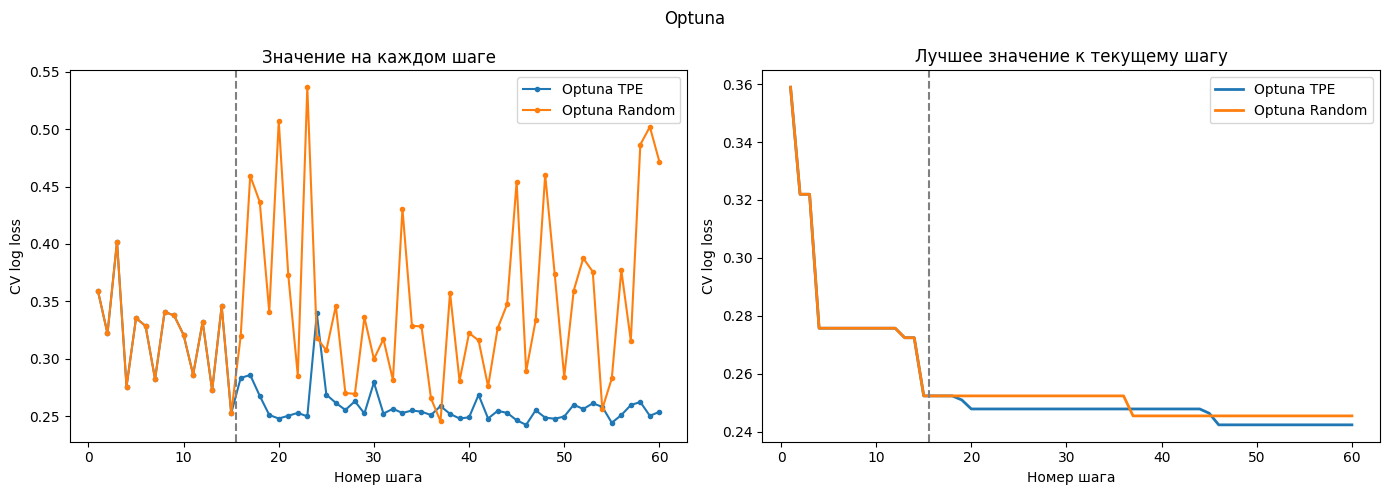

In [ ]:
plot_steps(optuna_results, "Optuna")

### Пространство протестированных гиперпараметров

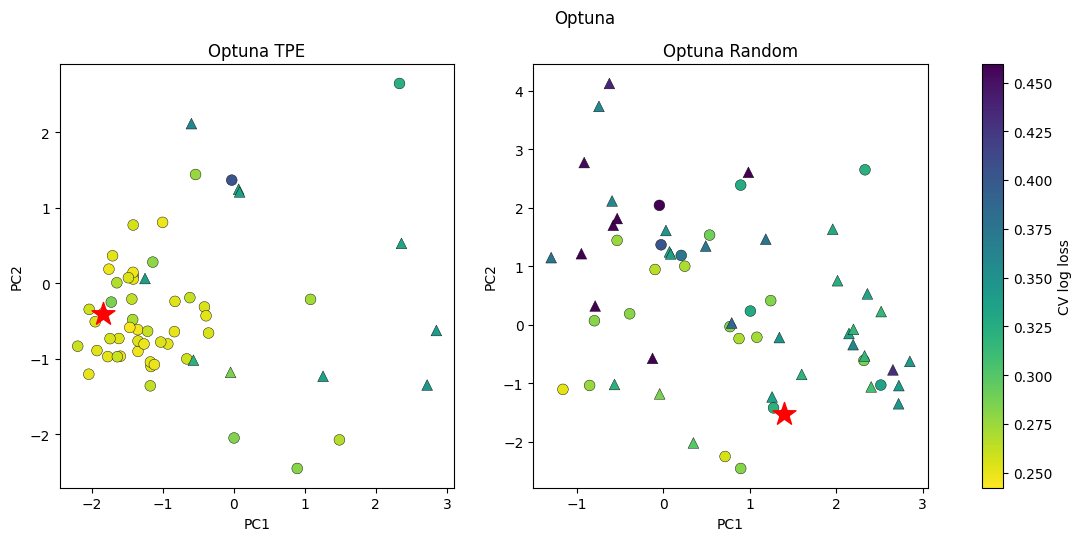

In [ ]:
plot_space(optuna_results, "Optuna")

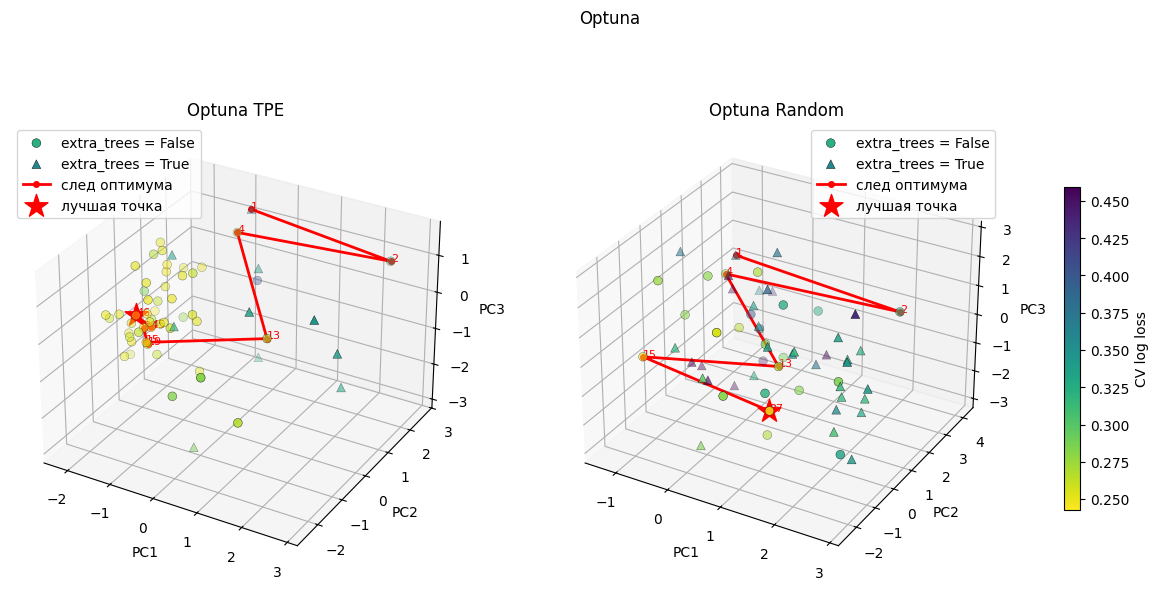

In [ ]:
plot_space_3d(optuna_results, "Optuna")

### Важность гиперпараметров

In [ ]:
for name, df in {**optuna_results}.items():
    table, oob = sobol_importance(df)
    print(f"{name}: OOB R^2 суррогата = {oob:.2f}")
    display(table.sort_values("ST", ascending=False).round(3))

Optuna TPE: OOB R^2 суррогата = 0.65


,S1,ST,ST_conf
extra_trees,0.729,0.805,0.062
num_leaves,0.161,0.226,0.026
min_split_gain,0.014,0.017,0.002
learning_rate,0.005,0.007,0.001
subsample,0.005,0.006,0.001
min_child_weight,0.005,0.005,0.001
max_bin,0.001,0.003,0.000
reg_alpha,0.003,0.002,0.000
colsample_bytree,0.001,0.002,0.000
min_child_samples,-0.000,0.002,0.000


Optuna Random: OOB R^2 суррогата = 0.77


,S1,ST,ST_conf
learning_rate,0.815,0.876,0.068
extra_trees,0.096,0.129,0.014
n_estimators,0.013,0.039,0.006
num_leaves,0.009,0.022,0.003
subsample_freq,0.003,0.003,0.000
min_child_weight,-0.001,0.002,0.000
reg_alpha,0.002,0.001,0.000
min_split_gain,-0.001,0.001,0.000
max_bin,-0.000,0.001,0.000
reg_lambda,-0.000,0.001,0.000


## Итог

In [ ]:
summary({**results, **optuna_results}, {**times, **optuna_times})

,лучший log loss,шаг лучшей точки,"время, с"
метод,,,
Байесовская оптимизация,0.2380,53,465.2
Случайный поиск,0.2435,32,90.1
Optuna TPE,0.2424,46,309.5
Optuna Random,0.2455,37,102.4


In [ ]:
NATURAL_LOW = ["min_split_gain", "reg_alpha", "reg_lambda", "min_child_weight"]
NATURAL_HIGH = ["subsample", "colsample_bytree"]


def check_bounds(results, top_share=0.1, edge=0.05, flag_share=0.2):
    data = pd.concat(results.values(), ignore_index=True)
    top = data[data["loss"] <= data["loss"].quantile(top_share)]
    features = feature_matrix(top)

    rows = []
    for index, (name, low, high, kind, log) in enumerate(SPACE):
        if kind == "bool":
            continue
        flow, fhigh = FEATURE_BOUNDS[index]
        position = (features[:, index] - flow) / (fhigh - flow)
        at_low = np.mean(position < edge)
        at_high = np.mean(position > 1 - edge)
        if at_high >= flag_share:
            verdict = "ок" if name in NATURAL_HIGH else "расширить вверх"
        elif at_low >= flag_share:
            verdict = "ок" if name in NATURAL_LOW else "расширить вниз"
        else:
            verdict = "ок"
        rows.append({
            "параметр": name,
            "диапазон": f"[{low}, {high}]",
            "медиана среди лучших": top[name].median(),
            "у нижней границы": round(at_low, 2),
            "у верхней границы": round(at_high, 2),
            "вывод": verdict,
        })

    print(f"Лучшие {top_share:.0%} конфигураций: {len(top)} точек")
    return pd.DataFrame(rows).set_index("параметр")


check_bounds({**results, **optuna_results})

Лучшие 10% конфигураций: 24 точек


,диапазон,медиана среди лучших,у нижней границы,у верхней границы,вывод
параметр,,,,,
n_estimators,"[50, 800]",5.615000e+02,0.00,0.00,ок
learning_rate,"[0.003, 0.3]",2.494512e-02,0.00,0.04,ок
num_leaves,"[4, 256]",9.100000e+01,0.00,0.00,ок
min_child_samples,"[5, 150]",1.750000e+01,0.00,0.00,ок
min_child_weight,"[0.0001, 10.0]",2.187481e-01,0.00,0.00,ок
min_split_gain,"[0.0, 1.0]",2.268622e-01,0.00,0.00,ок
subsample,"[0.5, 1.0]",8.774281e-01,0.00,0.04,ок
subsample_freq,"[1, 10]",6.000000e+00,0.00,0.00,ок
colsample_bytree,"[0.5, 1.0]",9.756867e-01,0.00,0.50,ок
